# VisionMatch AI — 02. CLIP Embedding Analysis

**Mục đích của notebook:** Kiểm tra và giải thích các vector đặc trưng ảnh (image embeddings) do CLIP tạo ra; quan sát chúng bằng thống kê, cosine similarity, ảnh Top-5 và PCA 2D.

**Câu hỏi cần trả lời:** (1) Embeddings có hợp lệ và khớp số ảnh không? (2) Hai ảnh có vector gần nhau có trông tương tự không? (3) Các nhóm `boot`, `sandal`, `shoe` phân bố ra sao?

**Nguồn dữ liệu:** [Cleanlab/footwear-demo trên Hugging Face](https://huggingface.co/datasets/Cleanlab/footwear-demo). Dataset gốc được tải bằng `scripts/download_dataset.py` và chuẩn bị bằng `scripts/prepare_dataset.py`; phần khám phá ảnh thô nằm ở `notebooks/01_dataset_exploration.ipynb`.

**Đầu vào của notebook:**
- `data/processed/catalog.csv`: metadata và đường dẫn ảnh, theo thứ tự hàng.
- `artifacts/clip_embeddings.npy`: ma trận vector đặc trưng đã được tạo bằng `scripts/build_index.py`.

**Thông tin từ lần chạy pipeline trước (không phải kết quả xác nhận từ notebook này):** 909 ảnh; `boot=305`, `sandal=301`, `shoe=303`; CLIP `openai/clip-vit-base-patch32` trên CUDA; embeddings `(909, 512)`, `float32`, NaN = 0, L2 norm ≈ 1.

**Phạm vi:** Notebook **chỉ đọc** ảnh, metadata và embeddings. Nó **không tải dataset, không chạy lại CLIP, không ghi đè `.npy` hoặc `.csv`**. Các biểu đồ và Top-5 mang tính *khám phá định tính*, chưa phải Recall@K/mAP@K.

---

## 0. Embedding Generation — Embeddings được tạo như thế nào?

Pipeline đã thực hiện **trước** notebook này:

`catalog.csv` → mở ảnh theo thứ tự hàng → CLIP processor → CLIP Image Encoder → chuẩn hóa L2 → `clip_embeddings.npy`

Chạy lại pipeline ở **terminal, từ thư mục gốc project**, chỉ khi cần tạo embeddings mới:

```powershell
python scripts/build_index.py
```

**Ý nghĩa:** Mỗi hàng `embeddings[i]` được dự định tương ứng với hàng `catalog.iloc[i]`. Nếu sửa/thêm/xóa/sắp xếp lại `catalog.csv` sau khi build, sự tương ứng có thể bị sai dù số hàng vẫn bằng nhau. Khi dữ liệu thay đổi, hãy chạy lại `prepare_dataset.py` rồi `build_index.py` trước khi mở notebook.

---

## 1. Load Embeddings — Đọc dữ liệu

**Mục đích cell:** Nạp 2 file đã tạo vào bộ nhớ, in số lượng ảnh, kích thước ma trận và kiểu dữ liệu.

**Cần hiểu:**
- `(909, 512)` nghĩa là **909 ảnh × 512 số cho mỗi ảnh**.
- `catalog` giúp chuyển từ chỉ số vector về đường dẫn ảnh và nhãn.
- Đây **chưa phải bước đánh giá chất lượng**.

**Kết quả kiểm soát:** số hàng embeddings bằng số dòng catalog; cả hai file phải tồn tại.

In [6]:
from pathlib import Path
import numpy as np
import pandas as pd

# Notebook located in notebooks/
PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "artifacts/clip_embeddings.npy").is_file():
    PROJECT_ROOT = PROJECT_ROOT.parent

EMBEDDINGS_PATH = PROJECT_ROOT / "artifacts/clip_embeddings.npy"
CATALOG_PATH = PROJECT_ROOT / "data/processed/catalog.csv"

if not EMBEDDINGS_PATH.is_file() or not CATALOG_PATH.is_file():
    raise FileNotFoundError(
        "Thiếu embeddings hoặc catalog. Hãy chạy prepare_dataset.py và build_index.py trước."
    )

embeddings = np.load(EMBEDDINGS_PATH, allow_pickle=False)
catalog = pd.read_csv(CATALOG_PATH)

print("Embedding shape:", embeddings.shape)
print("Catalog records:", len(catalog))
print("Embedding dtype:", embeddings.dtype)
display(catalog.head(5))


Embedding shape: (909, 512)
Catalog records: 909
Embedding dtype: float32


,image_id,image_path,category,width,height
0,0,data/raw/test-zip/boot/00980.jpg,boot,136,102
1,1,data/raw/test-zip/boot/00d04.jpg,boot,136,102
2,2,data/raw/test-zip/boot/01a4f.jpg,boot,136,102
3,3,data/raw/test-zip/boot/02677.jpg,boot,136,102
4,4,data/raw/test-zip/boot/037f2.jpg,boot,136,102


## 2. Embedding Validation — Kiểm tra vector

**Mục đích cell:** Xác nhận kết quả inference có cấu trúc hợp lệ trước khi tính độ tương đồng.

**Các phép kiểm tra:**
- `shape`: ma trận phải có 2 chiều và số vector khớp số dòng catalog.
- `NaN` / `Inf`: giá trị bất thường có thể làm hỏng phép tính similarity.
- **L2 norm ≈ 1**: độ dài mỗi vector xấp xỉ 1 sau chuẩn hóa.

**Kết quả kiểm soát:** không có NaN/Inf, min/max norm gần 1, các `assert` chạy qua.

**Giới hạn:** Kiểm tra này không xác nhận độ chính xác nhãn hoặc bảo đảm thứ tự ảnh-vector không bị thay đổi từ lúc build.

In [7]:
assert embeddings.ndim == 2, "Embeddings phải là ma trận 2 chiều."
assert len(catalog) == len(embeddings), "Số embeddings và số ảnh không khớp."
assert {"image_path", "category"}.issubset(catalog.columns), "Catalog thiếu cột bắt buộc."

norms = np.linalg.norm(embeddings, axis=1)
print("NaN count:", int(np.isnan(embeddings).sum()))
print("Inf count:", int(np.isinf(embeddings).sum()))
print("Min L2 norm:", float(norms.min()))
print("Max L2 norm:", float(norms.max()))

assert np.isfinite(embeddings).all(), "Embeddings có NaN hoặc Inf."
assert np.allclose(norms, 1.0, atol=1e-4), "Có vector chưa được chuẩn hóa L2."
print("All embedding checks passed!")

NaN count: 0
Inf count: 0
Min L2 norm: 0.9999998807907104
Max L2 norm: 1.0000001192092896
All embedding checks passed!


## 3. Category Analysis — Đếm nhãn ảnh

**Mục đích cell:** Nhìn lại số lượng ảnh của từng category trong **catalog mà embeddings đang tham chiếu**.

**Vì sao cần:** Phát hiện phân bố nhãn không đều hoặc danh mục bất ngờ trước khi diễn giải PCA/Top-5.

**Kết quả kiểm soát từ lần chuẩn bị dữ liệu trước:** `boot=305`, `sandal=301`, `shoe=303`; tổng = 909.

**Lưu ý:** Bảng này là thống kê nhãn được lấy từ thư mục ảnh, **không phải dự đoán phân loại của CLIP**.

In [8]:
category_counts = catalog["category"].value_counts().sort_index()
display(category_counts.rename("image_count").to_frame())
print("Total:", int(category_counts.sum()))

,image_count
category,
boot,305
sandal,301
shoe,303


Total: 909


## 4. Cosine Similarity — Độ giống nhau giữa hai vector

**Mục đích cell:** Thử tính điểm gần nhau giữa **một ảnh truy vấn có sẵn trong catalog** và những ảnh khác.

**Công thức:** Vì vector đã chuẩn hóa L2, `cosine_similarity(q, x) = q @ x` (tích vô hướng).

**Cách đọc kết quả:** Điểm lớn hơn → gần hơn trong không gian CLIP. Điểm gần 1 của ảnh với **chính nó** là điều bình thường; vì vậy cần loại chính ảnh truy vấn khi xem Top-5.

**Kết quả kiểm soát:** `similarity(query, query) ≈ 1`, và in ra Top-5 chỉ số khác query. Điểm số không phải xác suất.

In [9]:
QUERY_INDEX = 0  # Đổi thành số từ 0 đến len(catalog)-1 để xem truy vấn khác
assert 0 <= QUERY_INDEX < len(catalog)

scores = embeddings @ embeddings[QUERY_INDEX]
scores[QUERY_INDEX] = -np.inf  # Loại chính ảnh truy vấn
top5_indices = np.argsort(scores)[::-1][:5]

print("Query:", catalog.iloc[QUERY_INDEX]["image_path"])
print("Self cosine similarity:", float(embeddings[QUERY_INDEX] @ embeddings[QUERY_INDEX]))
display(pd.DataFrame({
    "rank": range(1, len(top5_indices) + 1),
    "image_path": catalog.iloc[top5_indices]["image_path"].to_numpy(),
    "category": catalog.iloc[top5_indices]["category"].to_numpy(),
    "cosine_similarity": scores[top5_indices]
}))

Query: data/raw/test-zip/boot/00980.jpg
Self cosine similarity: 1.0


,rank,image_path,category,cosine_similarity
0,1,data/raw/test-zip/boot/c8220.jpg,boot,0.955574
1,2,data/raw/test-zip/boot/ed41d.jpg,boot,0.955208
2,3,data/raw/test-zip/boot/178a0.jpg,boot,0.950270
3,4,data/raw/test-zip/boot/77163.jpg,boot,0.949800
4,5,data/raw/test-zip/boot/8448c.jpg,boot,0.947974


## 5. Top-5 Retrieval — Quan sát ảnh thật

**Mục đích cell:** Biến bảng điểm cosine thành **ảnh truy vấn + 5 ảnh gần nhất** để đánh giá định tính xem CLIP ưu tiên kiểu dáng, loại giày hay màu sắc.

**Cách sử dụng:** Thay `QUERY_INDEX` ở cell trước và chạy lại cell 4 rồi cell 5. Chỉ số là vị trí hàng trong `catalog.csv`.

**Cần quan sát:** Có đúng loại sản phẩm? Giống hình dáng? Ảnh sai có thể do góc chụp, nền, màu? Hãy thử nhiều query thay vì kết luận từ một trường hợp.

**Giới hạn:** Ảnh truy vấn ở đây thuộc chính catalog; khi có ảnh ngoài catalog, bài toán sẽ cần encode ảnh truy vấn riêng trong `search.py`.

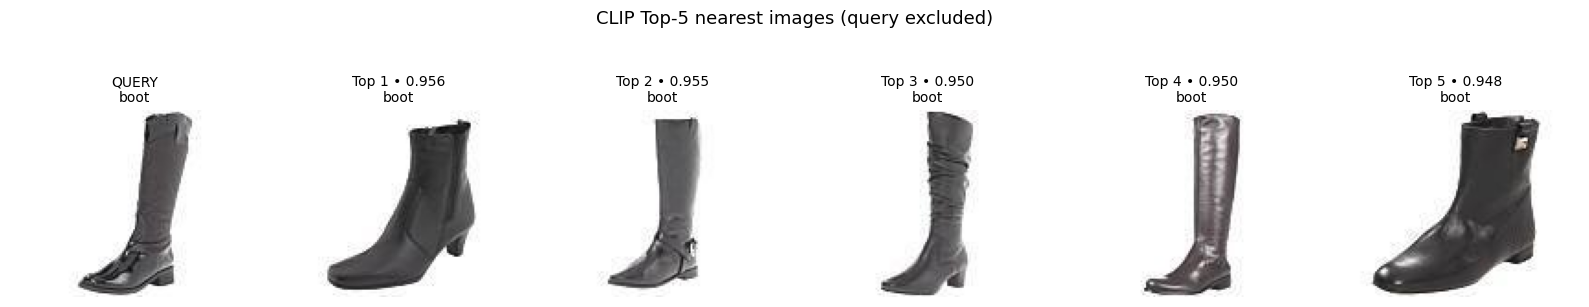

In [10]:
import matplotlib.pyplot as plt
from PIL import Image

display_indices = [QUERY_INDEX, *top5_indices.tolist()]
fig, axes = plt.subplots(1, len(display_indices), figsize=(16, 3.7))

for position, (ax, idx) in enumerate(zip(axes, display_indices)):
    row = catalog.iloc[idx]
    image_path = PROJECT_ROOT / row["image_path"]
    with Image.open(image_path) as img:
        ax.imshow(img.convert("RGB"))

    heading = ("QUERY" if position == 0
               else f"Top {position} • {scores[idx]:.3f}")
    ax.set_title(f"{heading}\n{row['category']}", fontsize=10)
    ax.axis("off")

plt.suptitle("CLIP Top-5 nearest images (query excluded)", fontsize=13)
plt.tight_layout()
plt.show()

## 6. PCA 2D — Trực quan hóa phân bố embeddings

**Mục đích cell:** Giảm 512 chiều xuống 2 chiều để vẽ một điểm cho mỗi ảnh, tô màu theo `category`.

**Cách đọc biểu đồ:** Các nhóm điểm có tách nhau hay chồng lấn? `explained_variance_ratio_.sum()` cho biết **tỷ lệ biến thiên dữ liệu** được hai trục PCA giữ lại.

**Cảnh báo:** PCA làm mất thông tin, nên nhóm tách biệt trong 2D **không chứng minh** hệ thống retrieval chính xác; nhóm chồng nhau cũng không chứng minh CLIP thất bại.

**Chuẩn bị môi trường:** Nếu thiếu thư viện, chạy trong terminal `python -m pip install scikit-learn matplotlib` rồi chọn lại kernel `.venv`.

In [11]:
%pip install scikit-learn

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.1 -> 26.2.2
[notice] To update, run: C:\Users\Lenovo\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


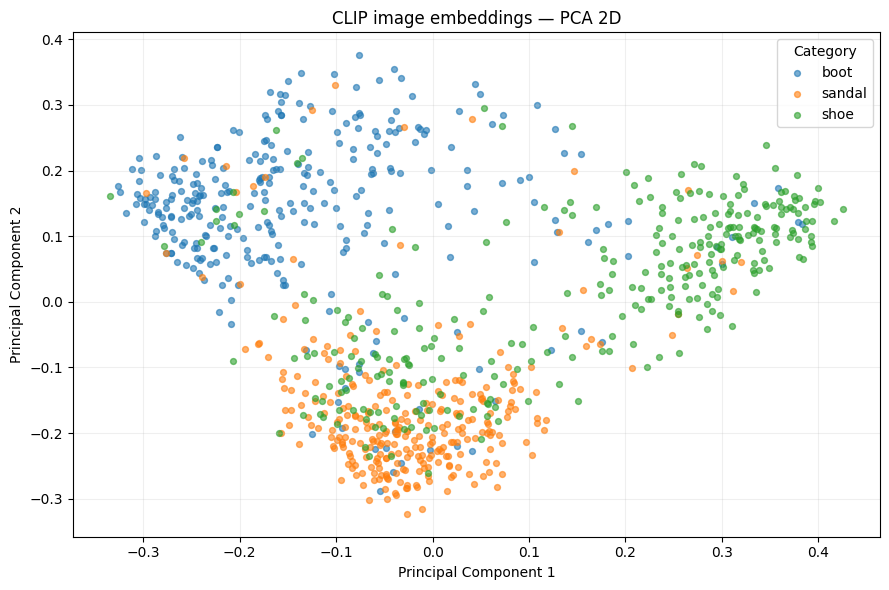

Variance explained by 2 PCs: 0.26360049843788147


In [13]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
coordinates = pca.fit_transform(embeddings)

plt.figure(figsize=(9, 6))
for category in sorted(catalog["category"].dropna().unique()):
    mask = (catalog["category"] == category).to_numpy()
    plt.scatter(
        coordinates[mask, 0], coordinates[mask, 1],
        label=category, alpha=0.6, s=18
    )

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("CLIP image embeddings — PCA 2D")
plt.legend(title="Category")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()
print("Variance explained by 2 PCs:", float(pca.explained_variance_ratio_.sum()))

## 7. Findings & Next Steps — Tổng kết sau khi chạy

Sau **Run All**, hãy ghi nhận dựa trên kết quả bạn thấy:

- **Kiểm tra kỹ thuật:** Có bao nhiêu vector? NaN/Inf? Norm có gần 1 không?
- **Top-5:** Với một số `QUERY_INDEX` thuộc `boot`, `sandal`, `shoe`, các ảnh gần nhất có hợp lý không? Ghi ví dụ tìm đúng và sai.
- **PCA:** Các nhóm có phân tách rõ trên hai thành phần chính không? Hai trục giữ lại bao nhiêu phần trăm biến thiên?

**Bước tiếp theo:** Xây dựng `scripts/search.py` để nhận ảnh query, trả Top-K theo cosine similarity. Sau đó chuẩn bị bộ query/ground truth và đo Recall@K, mAP@K để đánh giá định lượng.

**Ghi chú về tái lập:** Notebook sử dụng các file hiện có ở máy; kết quả chỉ còn đáng tin nếu `catalog.csv` và `.npy` được tạo từ cùng một lần build và đúng thứ tự.